# Crop Recommendation System — Exploratory Data Analysis & Model Exploration

This notebook explores the `Crop_recommendation.csv` dataset, checks data quality,
analyzes feature relationships, and prototypes the model comparison that
`src/train_model.py` runs as a script. Use this notebook for exploration;
`src/train_model.py` is the source of truth for the artifact the app actually loads.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_preprocessing import load_dataset, clean_dataset, FEATURE_COLUMNS, TARGET_COLUMN

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

## 1. Load the data

In [2]:
df = load_dataset()
print(df.shape)
df.head()

(2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 2. Data quality checks

In [3]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nCrop classes:", df[TARGET_COLUMN].nunique())
df[TARGET_COLUMN].value_counts()

Missing values per column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0

Crop classes: 22


label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

In [4]:
df_clean = clean_dataset(df)
df_clean.describe()

Missing values found: 0
Duplicate rows found: 0


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## 3. Feature distributions

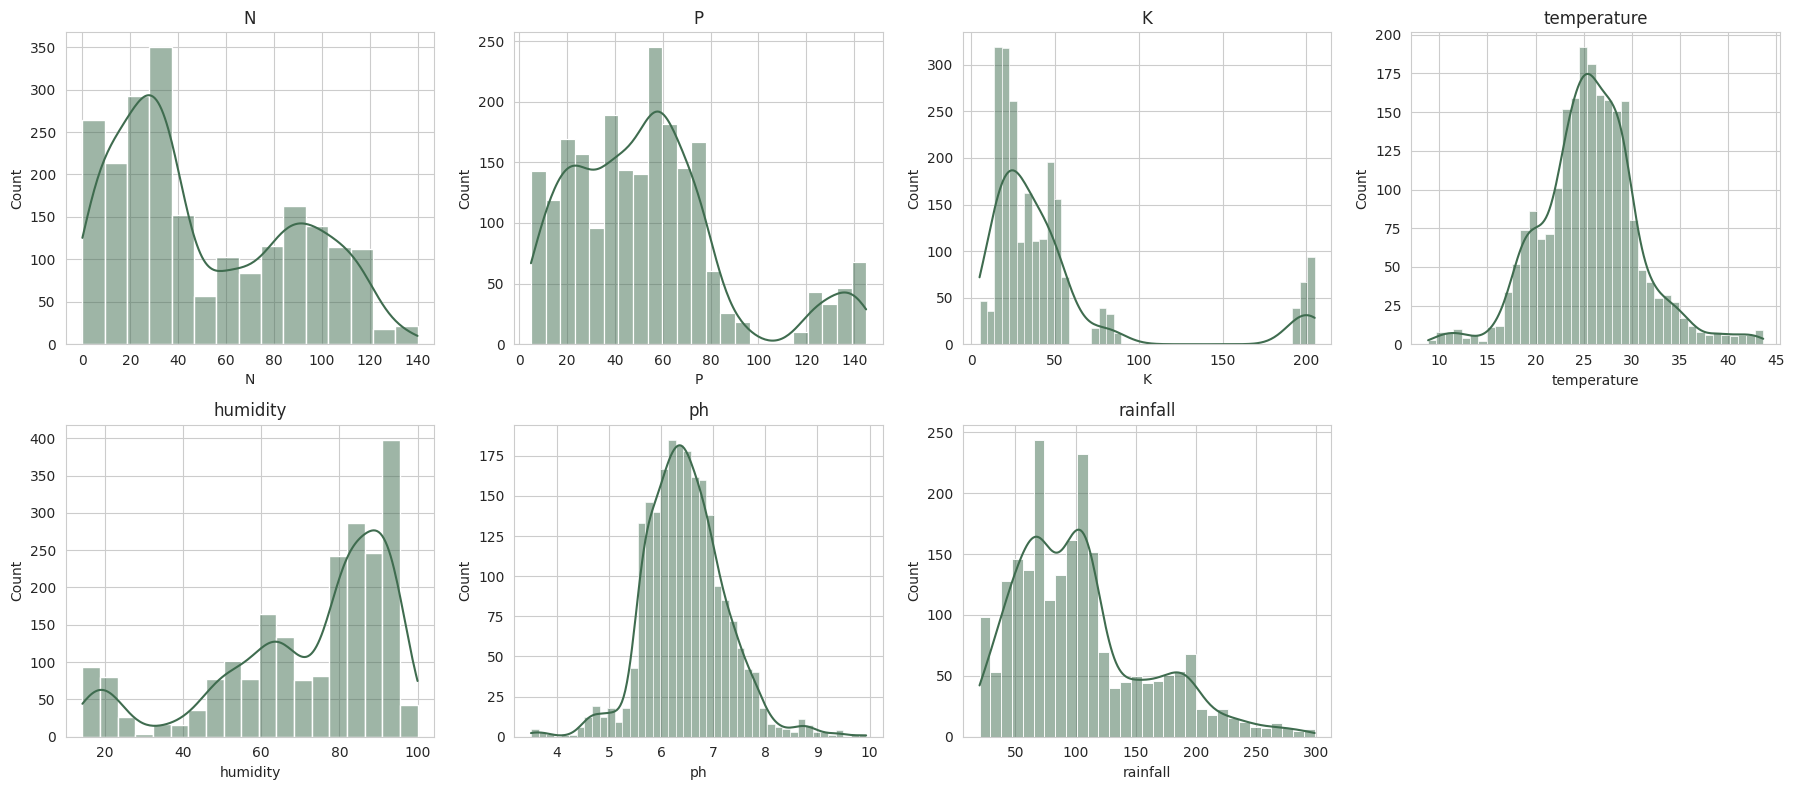

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, FEATURE_COLUMNS):
    sns.histplot(df_clean[col], kde=True, ax=ax, color='#3F6C4F')
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

## 4. Correlation analysis

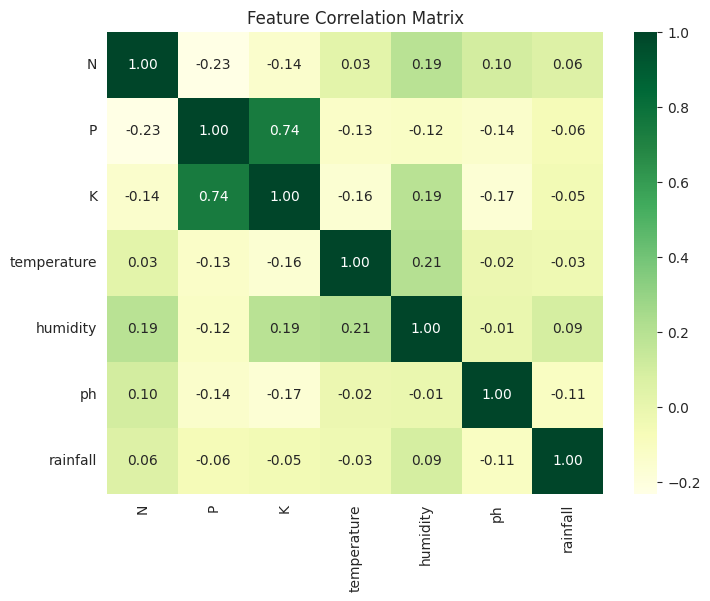

In [6]:
corr = df_clean[FEATURE_COLUMNS].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='YlGn', fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.show()

Phosphorus (P) and Potassium (K) show the strongest pairwise correlation among the
inputs, which makes intuitive sense as fertilizer nutrients that are often co-applied.
No pair is so highly correlated that it suggests dropping a feature.

## 5. Feature relationships with crop type

/tmp/ipykernel_688/2162271007.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')


/tmp/ipykernel_688/2162271007.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_688/2162271007.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')


/tmp/ipykernel_688/2162271007.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_688/2162271007.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')


/tmp/ipykernel_688/2162271007.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_688/2162271007.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')


/tmp/ipykernel_688/2162271007.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_688/2162271007.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')


/tmp/ipykernel_688/2162271007.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_688/2162271007.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')


/tmp/ipykernel_688/2162271007.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
/tmp/ipykernel_688/2162271007.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')


/tmp/ipykernel_688/2162271007.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


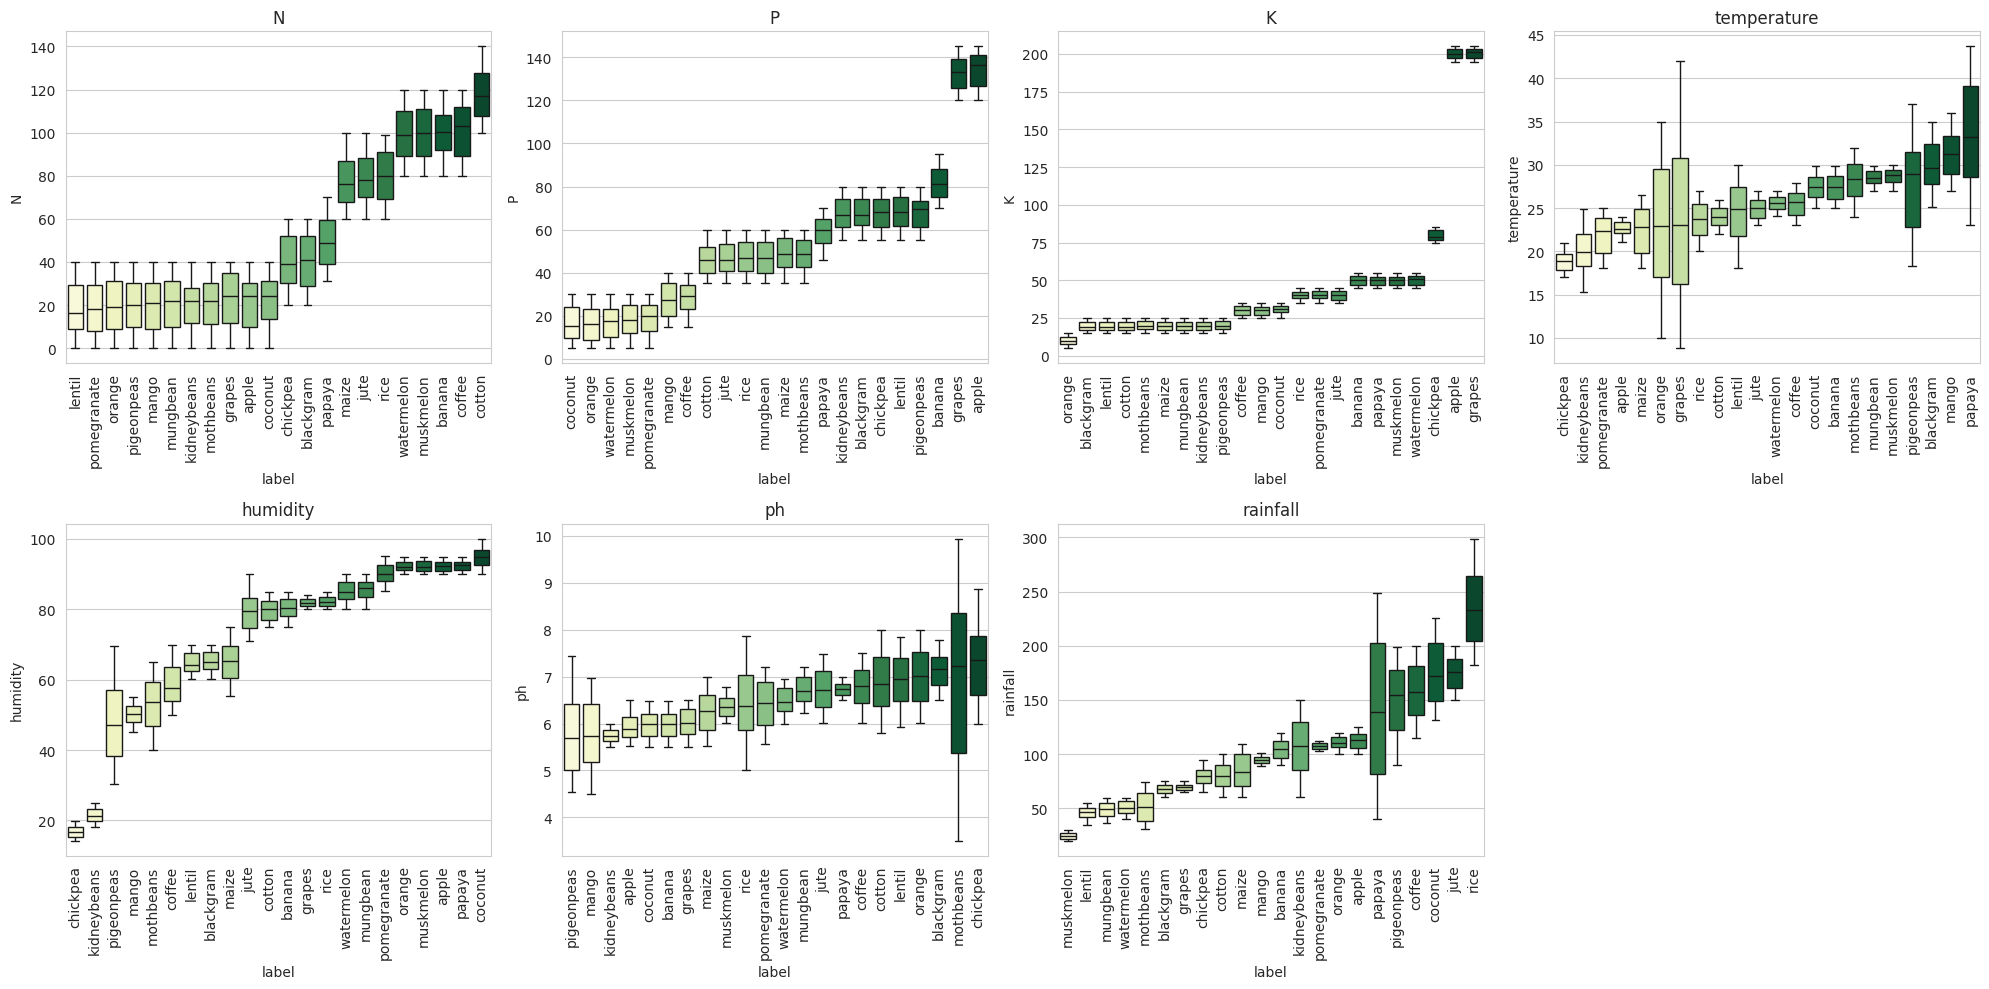

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for ax, col in zip(axes.flat, FEATURE_COLUMNS):
    order = df_clean.groupby(TARGET_COLUMN)[col].median().sort_values().index
    sns.boxplot(data=df_clean, x=TARGET_COLUMN, y=col, order=order, ax=ax, palette='YlGn')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

## 6. Model comparison (prototype)

This mirrors the logic in `src/train_model.py` — run that script to produce the actual saved artifact.

In [8]:
from src.data_preprocessing import get_feature_target_split, train_test_split_data
from src.train_model import build_candidate_models
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

X, y = get_feature_target_split(df_clean)
le = LabelEncoder()
y_enc = le.fit_transform(y)
X_train, X_test, y_train, y_test = train_test_split_data(X, y_enc)

results = []
for name, model in build_candidate_models().items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds, average='weighted'),
    })

results_df = pd.DataFrame(results).sort_values('F1-Score', ascending=False)
results_df

,Model,Accuracy,F1-Score
2,Random Forest,0.995455,0.995452
5,XGBoost,0.988636,0.988559
0,Logistic Regression,0.984091,0.983993
4,SVM (RBF Kernel),0.984091,0.983908
1,Decision Tree,0.979545,0.979423
3,K-Nearest Neighbors,0.977273,0.977231


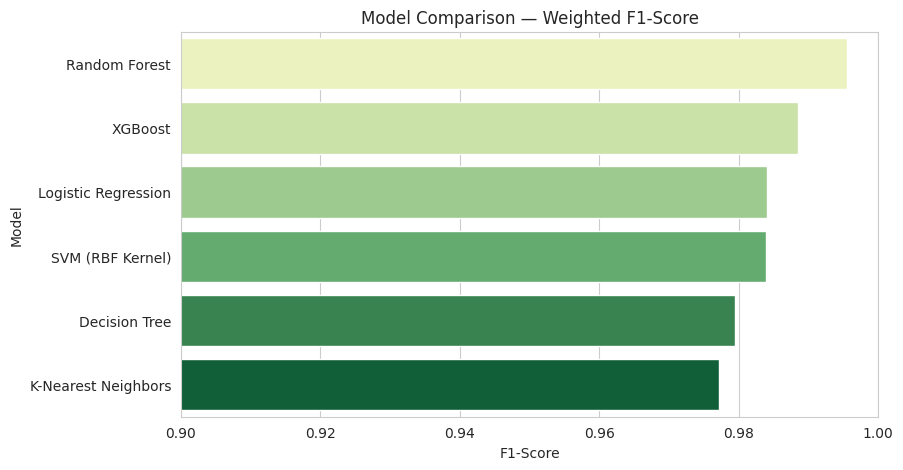

In [9]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x='F1-Score', y='Model', palette='YlGn')
plt.xlim(0.9, 1.0)
plt.title('Model Comparison — Weighted F1-Score')
plt.show()

## 7. Conclusion

Random Forest (and closely, XGBoost) achieve the strongest performance on this dataset,
consistent with the fact that crop-vs-condition boundaries are non-linear and benefit from
ensembles of decision trees. See `src/train_model.py` for the script that trains, compares,
and saves the deployed model, and `src/evaluate_model.py` for the full classification
report and confusion matrix used in the Streamlit dashboard.